<a href="https://colab.research.google.com/github/idaniilmarkovi-stack/python-lab1-food/blob/main/03_colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 03. Google Colab: исследование отладочного среза
Блокнот самодостаточен (не импортирует `src`) и запускается в Colab. Срез (`debug_200k.csv`) загружается с компьютера кнопкой в ячейке 4 либо с Google Диска.

## 1. Версия интерпретатора Colab
В курсе требуется 3.12.14; Colab задаёт версию сам, поэтому результат лишь проверяется, а не сдаётся из Colab.

In [1]:
import sys
print(sys.version)
print('совпадает с 3.12.14:', sys.version.startswith('3.12.14'))

3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
совпадает с 3.12.14: False


## 2. Установка библиотек
Команда с восклицательным знаком выполняется в оболочке сеанса.

In [2]:
!pip install -q pandas polars
import pandas as pd, polars as pl
print('pandas', pd.__version__, '| polars', pl.__version__)

pandas 2.2.3 | polars 1.35.2


## 3. Загрузка среза
Вариант А — прямая загрузка файла. Вариант Б (закомментирован) — подключение Google Диска.

In [3]:
from google.colab import files
uploaded = files.upload()          # выберите debug_200k.csv
path = next(iter(uploaded))
# from google.colab import drive; drive.mount('/content/drive'); path = '/content/drive/MyDrive/debug_200k.csv'
path

Saving debug_200k.csv to debug_200k.csv


'debug_200k.csv'

## 4. Чтение, размер, типы и доля пропусков

In [4]:
df = pd.read_csv(path, low_memory=False)
print('строк:', df.shape[0], 'столбцов:', df.shape[1])
info = pd.DataFrame({'тип': df.dtypes.astype(str), 'пропусков, %': (df.isna().mean() * 100).round(2)})
info

строк: 200000 столбцов: 21


,тип,"пропусков, %"
fdc_id,int64,0.00
brand_owner,object,0.41
brand_name,object,100.00
subbrand_name,float64,100.00
gtin_upc,object,0.00
ingredients,object,0.43
not_a_significant_source_of,float64,100.00
serving_size,float64,0.00
serving_size_unit,object,0.00
household_serving_fulltext,object,17.16


## 5. График: число записей по годам изменения (`modified_date`)

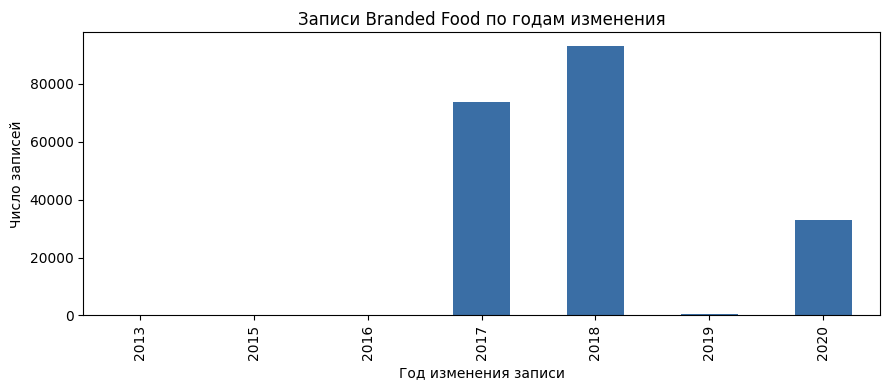

In [5]:
import matplotlib.pyplot as plt
years = pd.to_datetime(df['modified_date'], errors='coerce').dt.year.value_counts().sort_index()
ax = years.plot(kind='bar', figsize=(9, 4), color='#3a6ea5')
ax.set_xlabel('Год изменения записи'); ax.set_ylabel('Число записей'); ax.set_title('Записи Branded Food по годам изменения')
plt.tight_layout(); plt.show()

**Вывод.** Основная масса записей изменена в последние годы наблюдений: набор — «слепок» базы на дату выгрузки, а не равномерная история.